# Module 5 · A learning machine that recognises neuron types

An artificial neuron keeps three operations of a biological one: **weigh** its inputs, **add** them, and **decide** through a nonlinearity. It drops voltage, time and spikes, and gains a learning rule (backpropagation).

Here we close the loop with Module 3: we simulate 600 heterogeneous Izhikevich cells (five classes, random parameters, currents and noise), describe each spike train with five features, and train a small network to recognise the class, as an electrophysiologist would. A multinomial logistic regression (no hidden layer) is the statistical baseline.

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
X, y, trains = ns.make_dataset(n_per_class=120, seed=0)
print(X.shape, 'features:', ns.FEATURES)
for k, key in enumerate(ns.CLASS_KEYS):
    print(f'{key:4s}', np.round(X[y == k].mean(0), 2))

(600, 5) features: ['log rate', 'CV of ISI', 'adaptation', 'burst fraction', 'first-spike latency']
RS   [1.4  0.19 0.41 0.02 4.63]
IB   [1.59 0.58 0.57 0.3  4.74]
CH   [1.93 1.52 0.31 0.8  4.86]
FS   [2.05 0.19 0.23 0.6  4.54]
LTS  [1.88 0.33 0.54 0.3  3.43]


In [3]:
print(inspect.getsource(ns.SpikeClassNet._layers))
print(inspect.getsource(ns.SpikeClassNet.fit))

    def _layers(self, Z):
        """Return the activity of every layer; the last one is class probabilities."""
        acts = [Z]
        for k, (W, b) in enumerate(zip(self.W, self.b)):
            z = acts[-1] @ W + b                    # weigh and add
            if k < len(self.W) - 1:
                acts.append(np.maximum(z, 0.0))      # decide: ReLU
            else:
                z = z - z.max(axis=1, keepdims=True)
                e = np.exp(z)
                acts.append(e / e.sum(axis=1, keepdims=True))   # softmax
        return acts

    def fit(self, X, y, epochs=300, batch=32, lr=0.05, momentum=0.9, l2=1e-4,
            X_val=None, y_val=None, seed=0):
        """Train and return a history of training / validation loss and accuracy."""
        rng = np.random.default_rng(seed)
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-9
        Z = self._standardise(X)
        Y = np.eye(self.W[-1].shape[1])[y]
        hist = {"train_loss": [], "val_loss": [], "train_acc": 

In [4]:
train, test = ns.stratified_split(y, 0.3, seed=0)
net = ns.SpikeClassNet(5, 5, hidden=(16, 16), seed=0)
hist = net.fit(X[train], y[train], epochs=150, X_val=X[test], y_val=y[test])
base = ns.SpikeClassNet(5, 5, hidden=(), seed=0); base.fit(X[train], y[train], epochs=150)
for name, model in (('MLP', net), ('logistic', base)):
    pred = model.predict(X[test])
    print(f"{name:8s} accuracy {np.mean(pred == y[test]):.3f}  macro-F1 {ns.macro_f1(y[test], pred, 5):.3f}")
print(ns.confusion_matrix(y[test], net.predict(X[test]), 5))

MLP      accuracy 0.956  macro-F1 0.955
logistic accuracy 0.939  macro-F1 0.938
[[36  0  0  0  0]
 [ 4 31  1  0  0]
 [ 0  1 35  0  0]
 [ 0  0  0 35  1]
 [ 0  1  0  0 35]]


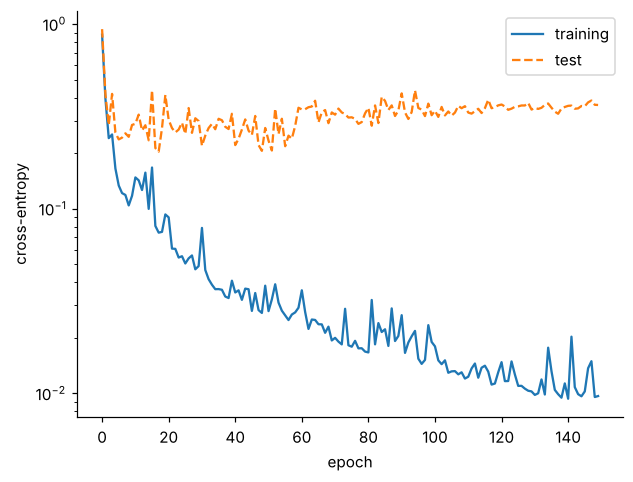

In [5]:
plt.semilogy(hist['train_loss'], label='training'); plt.semilogy(hist['val_loss'], '--', label='test')
plt.xlabel('epoch'); plt.ylabel('cross-entropy'); plt.legend(); plt.show()

## An honest evaluation
One split is one draw. We repeat the split ten times; because the ten training sets share most of their cells, a naive interval is too narrow, so we use the corrected resampled t interval of Nadeau and Bengio. Then, because simulated data are free, we test both models on 600 **new** cells and compare them cell by cell (McNemar test) and by the quality of their probabilities (Brier score, calibration error).

In [6]:
acc = {'MLP': [], 'LR': []}
for s in range(10):
    tr, te = ns.stratified_split(y, 0.3, seed=s)
    for name, hid in (('MLP', (16, 16)), ('LR', ())):
        m = ns.SpikeClassNet(5, 5, hid, seed=s); m.fit(X[tr], y[tr], epochs=150, seed=s)
        acc[name].append(np.mean(m.predict(X[te]) == y[te]))
for name, v in acc.items():
    c = ns.corrected_resampled_t(v, 420, 180)
    naive = 1.96 * np.std(v, ddof=1) / np.sqrt(10)
    print(f"{name}: {c['mean']:.3f}  corrected 95% CI {c['lower']:.3f}-{c['upper']:.3f}  (naive +/-{naive:.3f})")
d = ns.corrected_resampled_t(np.subtract(acc['MLP'], acc['LR']), 420, 180)
print(f"difference {d['mean']:+.3f}, 95% CI {d['lower']:+.3f} to {d['upper']:+.3f}, p = {d['p']:.2f}")

MLP: 0.955  corrected 95% CI 0.934-0.976  (naive +/-0.008)
LR: 0.947  corrected 95% CI 0.936-0.957  (naive +/-0.004)
difference +0.008, 95% CI -0.016 to +0.033, p = 0.46


In [7]:
Xn, yn, _ = ns.make_dataset(n_per_class=120, seed=1)          # 600 new cells
mlp = ns.SpikeClassNet(5, 5, (16, 16), seed=0); mlp.fit(X, y, epochs=150, seed=0)
lr  = ns.SpikeClassNet(5, 5, (), seed=0);       lr.fit(X, y, epochs=150, seed=0)
for name, m in (('MLP', mlp), ('LR', lr)):
    P = m.predict_proba(Xn); ece = ns.calibration_curve(P, yn)[3]
    print(f"{name}: accuracy {np.mean(P.argmax(1) == yn):.3f}  Brier {ns.brier_score(P, yn):.3f}  ECE {ece:.3f}")
print('McNemar:', ns.mcnemar_exact(mlp.predict(Xn) == yn, lr.predict(Xn) == yn))

MLP: accuracy 0.972  Brier 0.044  ECE 0.017
LR: accuracy 0.963  Brier 0.067  ECE 0.046
McNemar: {'n10': 16, 'n01': 11, 'p': 0.44206833839416504}


## Exercises
1. Compare the corrected and the naive intervals above. Why is the naive one about three times narrower, and which would you trust? Is the MLP really better than logistic regression?
2. Train with only two features (burst fraction and CV). Which classes become confused, and why?
3. Remove the ReLU (make the hidden layers linear). What does the network become?
4. The test loss creeps up after a few dozen epochs while test accuracy stays flat. What is this called, and how would you prevent it?
5. List what the artificial neuron keeps and discards compared with Modules 1-3.